In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
male = pd.read_csv(
    'ANSUR_II_MALE_Public.csv',
    encoding='cp1252'
)

female = pd.read_csv('ANSUR_II_FEMALE_Public.csv')

print("Male data:", male.shape)
print("Female data:", female.shape)

display(male.head())
display(female.head())

Male data: (4082, 108)
Female data: (1986, 108)


,subjectid,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,...,Branch,PrimaryMOS,SubjectsBirthLocation,SubjectNumericRace,Ethnicity,DODRace,Age,Heightin,Weightlbs,WritingPreference
0,10027,266,1467,337,222,1347,253,202,401,369,...,Combat Arms,19D,North Dakota,1,NaN,1,41,71,180,Right hand
1,10032,233,1395,326,220,1293,245,193,394,338,...,Combat Support,68W,New York,1,NaN,1,35,68,160,Left hand
2,10033,287,1430,341,230,1327,256,196,427,408,...,Combat Support,68W,New York,2,NaN,2,42,68,205,Left hand
3,10092,234,1347,310,230,1239,262,199,401,359,...,Combat Service Support,88M,Wisconsin,1,NaN,1,31,66,175,Right hand
4,10093,250,1585,372,247,1478,267,224,435,356,...,Combat Service Support,92G,North Carolina,2,NaN,2,21,77,213,Right hand


,SubjectId,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,...,Branch,PrimaryMOS,SubjectsBirthLocation,SubjectNumericRace,Ethnicity,DODRace,Age,Heightin,Weightlbs,WritingPreference
0,10037,231,1282,301,204,1180,222,177,373,315,...,Combat Support,92Y,Germany,2,NaN,2,26,61,142,Right hand
1,10038,194,1379,320,207,1292,225,178,372,272,...,Combat Service Support,25U,California,3,Mexican,3,21,64,120,Right hand
2,10042,183,1369,329,233,1271,237,196,397,300,...,Combat Service Support,35D,Texas,1,NaN,1,23,68,147,Right hand
3,10043,261,1356,306,214,1250,240,188,384,364,...,Combat Service Support,25U,District of Columbia,8,Caribbean Islander,2,22,66,175,Right hand
4,10051,309,1303,308,214,1210,217,182,378,320,...,Combat Arms,42A,Texas,1,NaN,1,45,63,195,Right hand


In [3]:
female = female.rename(columns={'SubjectId': 'subjectid'})

assert male.columns.equals(female.columns)

df = pd.concat([male, female], ignore_index=True)

df['Gender'] = df['Gender'].str.strip()

print("Combined shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()
df = df[df['Gender'].isin(['Female', 'Male'])].copy()

display(df['Gender'].value_counts())

Combined shape: (6068, 108)
Duplicate rows: 0


Gender
Male      4082
Female    1986
Name: count, dtype: int64

In [4]:
features = male.loc[
    :,
    'abdominalextensiondepthsitting':'wristheight'
].columns.tolist()

df[features] = df[features].apply(
    pd.to_numeric,
    errors='coerce'
)

print("Number of body measurements:", len(features))

missing_values = df[features].isnull().sum()

print("Total missing measurement values:", missing_values.sum())

display(missing_values[missing_values > 0])
display(df[features].describe())

Number of body measurements: 93
Total missing measurement values: 0


Series([], dtype: int64)

,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,bicristalbreadth,...,verticaltrunkcircumferenceusa,waistbacklength,waistbreadth,waistcircumference,waistdepth,waistfrontlengthsitting,waistheightomphalion,weightkg,wristcircumference,wristheight
count,6068.000000,6068.000000,6068.000000,6068.000000,6068.000000,6068.00000,6068.000000,6068.000000,6068.000000,6068.000000,...,6068.000000,6068.000000,6068.000000,6068.000000,6068.000000,6068.000000,6068.000000,6068.000000,6068.000000,6068.000000
mean,246.468688,1406.161338,327.374423,224.891397,1299.608767,244.19265,194.754614,399.204186,340.934245,274.735003,...,1630.309492,460.524720,317.750000,914.501483,229.674028,377.003790,1031.501154,797.093935,169.002966,830.059987
std,37.400106,79.091048,20.720018,16.051833,72.022286,16.84502,13.516368,30.236914,41.519866,19.221034,...,98.624125,36.677909,36.363125,114.274513,35.613193,31.617723,62.702388,156.528164,13.124513,47.650519
min,155.000000,1115.000000,249.000000,156.000000,1038.000000,186.00000,151.000000,283.000000,216.000000,197.000000,...,1342.000000,345.000000,211.000000,611.000000,138.000000,289.000000,805.000000,358.000000,124.000000,672.000000
25%,219.000000,1350.000000,313.000000,214.000000,1249.000000,232.00000,185.000000,376.000000,311.000000,262.000000,...,1558.000000,435.000000,292.000000,829.000000,203.000000,355.000000,988.000000,682.000000,159.000000,797.000000
50%,242.000000,1410.000000,328.000000,225.000000,1302.000000,245.00000,195.000000,404.000000,341.000000,274.000000,...,1628.000000,463.000000,316.000000,907.000000,226.000000,375.000000,1033.000000,785.000000,170.000000,830.000000
75%,271.000000,1462.000000,341.250000,235.000000,1349.000000,256.00000,204.000000,421.000000,370.000000,288.000000,...,1695.000000,486.000000,343.000000,992.000000,252.250000,398.000000,1076.000000,896.000000,179.000000,863.000000
max,451.000000,1683.000000,393.000000,293.000000,1553.000000,306.00000,245.000000,489.000000,490.000000,362.000000,...,1991.000000,598.000000,461.000000,1379.000000,406.000000,494.000000,1245.000000,1442.000000,216.000000,1009.000000


In [5]:
df['Height_cm'] = df['stature'] / 10

height_summary = df.groupby('Gender')['Height_cm'].agg(
    ['count', 'mean', 'std', 'min', 'max']
)

display(height_summary.round(2))

,count,mean,std,min,max
Gender,,,,,
Female,1986,162.85,6.42,140.9,182.9
Male,4082,175.62,6.86,149.1,199.3


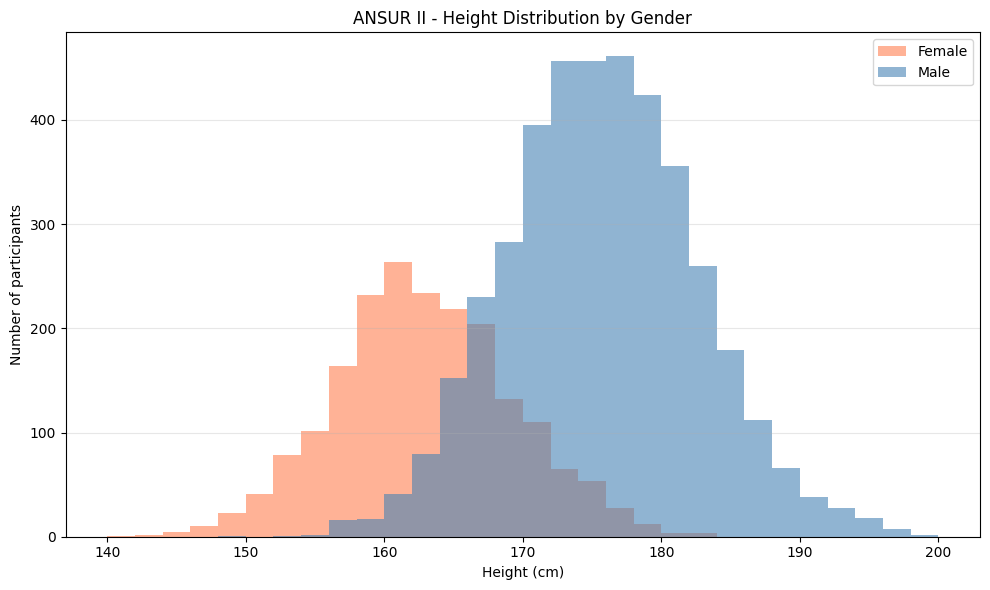

In [6]:
female_heights = df.loc[
    df['Gender'] == 'Female',
    'Height_cm'
]

male_heights = df.loc[
    df['Gender'] == 'Male',
    'Height_cm'
]

bins = np.arange(140, 202, 2)

plt.figure(figsize=(10, 6))

plt.hist(
    female_heights,
    bins=bins,
    alpha=0.6,
    color='coral',
    label='Female'
)

plt.hist(
    male_heights,
    bins=bins,
    alpha=0.6,
    color='steelblue',
    label='Male'
)

plt.title('ANSUR II - Height Distribution by Gender')
plt.xlabel('Height (cm)')
plt.ylabel('Number of participants')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
X = df[features].copy()

y = df['Gender'].map({
    'Female': 0,
    'Male': 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (4854, 93)
Test shape: (1214, 93)


In [8]:
train_medians = X_train.median()

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

assert not X_train.isnull().any().any()
assert not X_test.isnull().any().any()

assert X_train.columns.equals(X_test.columns)

In [9]:
dtree = DecisionTreeClassifier(
    random_state=42
)

dtree.fit(X_train, y_train)

tree_train_pred = dtree.predict(X_train)
tree_test_pred = dtree.predict(X_test)

In [10]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    max_samples=1.0,
    max_features=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)

bagging_train_pred = bagging_model.predict(X_train)
bagging_test_pred = bagging_model.predict(X_test)

In [11]:
comparison = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Bagging Decision Trees'
    ],
    'Training accuracy': [
        accuracy_score(y_train, tree_train_pred),
        accuracy_score(y_train, bagging_train_pred)
    ],
    'Test accuracy': [
        accuracy_score(y_test, tree_test_pred),
        accuracy_score(y_test, bagging_test_pred)
    ],
    'Test mistakes': [
        int((y_test != tree_test_pred).sum()),
        int((y_test != bagging_test_pred).sum())
    ]
})

display(comparison.round(4))

,Model,Training accuracy,Test accuracy,Test mistakes
0,Decision Tree,1.0,0.9786,26
1,Bagging Decision Trees,1.0,0.9876,15


In [12]:
print(classification_report(
    y_test,
    bagging_test_pred,
    labels=[0, 1],
    target_names=['Female', 'Male'],
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

      Female     0.9923    0.9698    0.9809       397
        Male     0.9855    0.9963    0.9909       817

    accuracy                         0.9876      1214
   macro avg     0.9889    0.9831    0.9859      1214
weighted avg     0.9877    0.9876    0.9876      1214



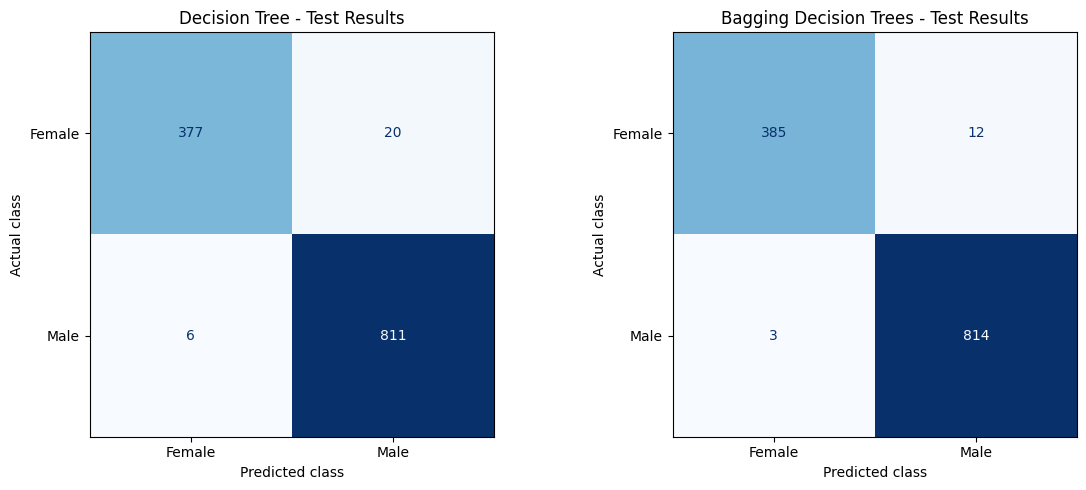

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name, predictions in [
    (axes[0], 'Decision Tree', tree_test_pred),
    (axes[1], 'Bagging Decision Trees', bagging_test_pred)
]:

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Female', 'Male']
    )

    disp.plot(
        ax=ax,
        cmap='Blues',
        values_format='d',
        colorbar=False
    )

    ax.set_title(f'{name} - Test Results')
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Actual class')

plt.tight_layout()
plt.show()

درخت تصمیم روی داده‌های تست حدود ۹۷٫۸۶٪ دقت داشت، درحالی‌که ترکیب ۱۰۰ درخت با روش بگینگ به دقت حدود ۹۸٫۷۶٪ رسید. تعداد پیش‌بینی‌های اشتباه هم از ۲۶ به ۱۵ کاهش پیدا کرد؛ بنابراین در این تقسیم‌بندی، ترکیب چند درخت از یک درخت تنها بهتر عمل کرد. دقت آموزش هر دو مدل ۱۰۰٪ بود، ولی نتیجه تست نشون داد مدل بگینگ روی داده‌هایی که در آموزش ندیده بود، عملکرد بهتری داشت.

طبق ماتریس درهم‌ریختگی بگینگ، از ۳۹۷ زن، تعداد ۳۸۵ نفر و از ۸۱۷ مرد، تعداد ۸۱۴ نفر درست طبقه‌بندی شدن. این نتیجه مربوط به داده‌های همین نمونه از کارکنان نظامی آمریکاست و به‌تنهایی عملکرد مدل رو برای جمعیت‌های دیگه مشخص نمی‌کنه.